Assignment 3. Implement forward propagation and backpropagation using TensorFlow/Keras. Analyze the effect of different learning rates and the number of epochs on model performance.

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Learning Rate = 0.1   Accuracy = 0.9561
Learning Rate = 0.01   Accuracy = 0.9649
Learning Rate = 0.001   Accuracy = 0.9561


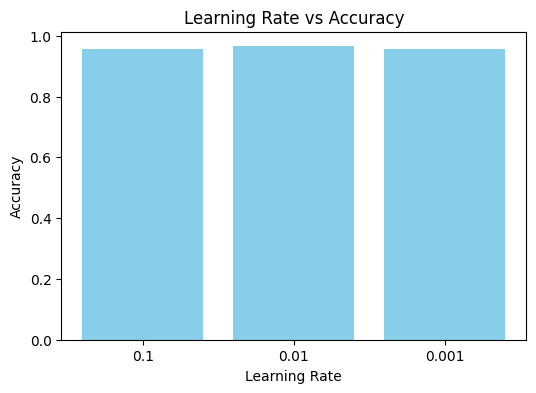

Epochs = 10   Accuracy = 0.9737
Epochs = 50   Accuracy = 0.9825
Epochs = 100   Accuracy = 0.9737


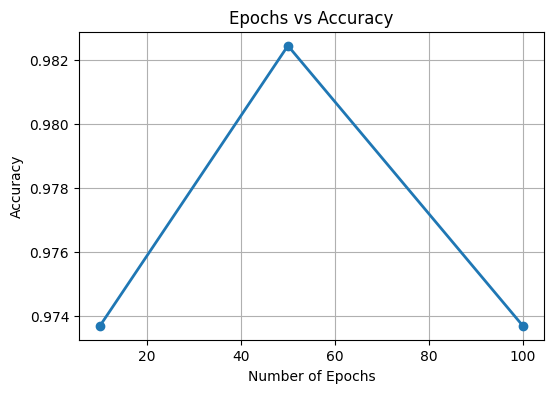

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6648 - loss: 0.6313 - val_accuracy: 0.8242 - val_loss: 0.5851
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8626 - loss: 0.4951 - val_accuracy: 0.8901 - val_loss: 0.4466
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9121 - loss: 0.3931 - val_accuracy: 0.9451 - val_loss: 0.3476
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9368 - loss: 0.3180 - val_accuracy: 0.9560 - val_loss: 0.2832
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9451 - loss: 0.2600 - val_accuracy: 0.9560 - val_loss: 0.2339
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9505 - loss: 0.2108 - val_accuracy: 0.9560 - val_loss: 0.1989
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9560 - loss: 0.1723 - val_accuracy: 0.9451 - val_loss: 0.1732
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9615 - loss: 0.1433 - val_accuracy: 0.9451 - 

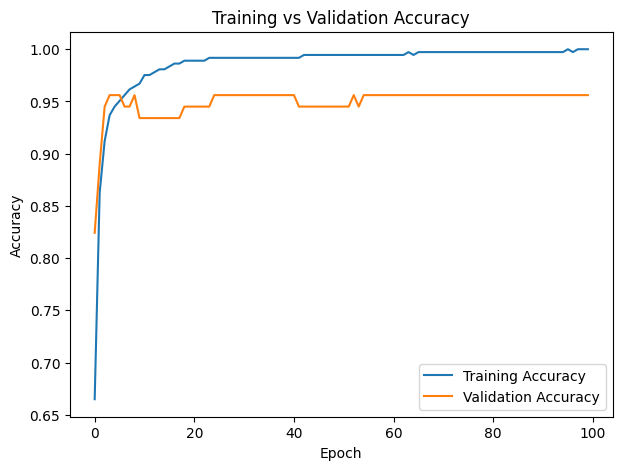

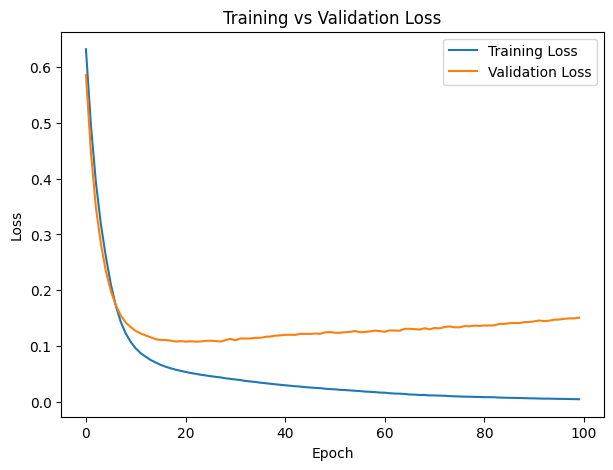

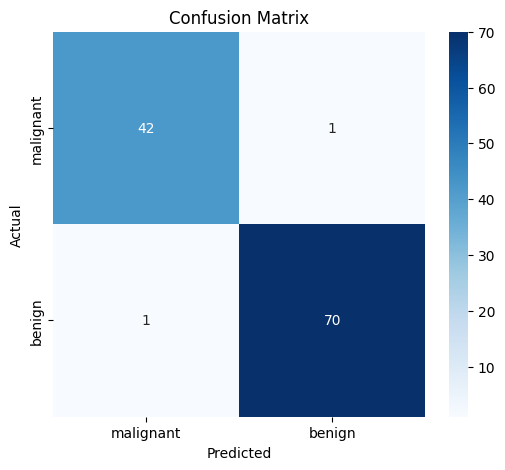

In [ ]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Load Dataset
cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

df = pd.DataFrame(X, columns=cancer.feature_names)
df["Target"] = y

print(df.head())

print("\nDataset Shape :", df.shape)

print("\nClass Distribution")
print(df["Target"].value_counts())

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Learning Rate Analysis
learning_rates = [0.1, 0.01, 0.001]

lr_accuracy = []

for lr in learning_rates:

    model = Sequential([
        Dense(16, activation='relu', input_shape=(30,)),
        Dense(8, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    optimizer = Adam(learning_rate=lr)

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=16,
        validation_split=0.2,
        verbose=0
    )

    loss, accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    lr_accuracy.append(accuracy)

    print(f"Learning Rate = {lr}   Accuracy = {accuracy:.4f}")

# Visualization 1
# Learning Rate vs Accuracy
plt.figure(figsize=(6,4))

plt.bar(
    [str(i) for i in learning_rates],
    lr_accuracy,
    color="skyblue"
)

plt.xlabel("Learning Rate")
plt.ylabel("Accuracy")
plt.title("Learning Rate vs Accuracy")

plt.show()

# Epoch Analysis
epochs_list = [10, 50, 100]

epoch_accuracy = []

for ep in epochs_list:

    model = Sequential([
        Dense(16, activation='relu', input_shape=(30,)),
        Dense(8, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    optimizer = Adam(learning_rate=0.001)

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    model.fit(
        X_train,
        y_train,
        epochs=ep,
        batch_size=16,
        validation_split=0.2,
        verbose=0
    )

    loss, accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    epoch_accuracy.append(accuracy)

    print(f"Epochs = {ep}   Accuracy = {accuracy:.4f}")


# Visualization 2
# Epochs vs Accuracy
plt.figure(figsize=(6,4))

plt.plot(
    epochs_list,
    epoch_accuracy,
    marker='o',
    linewidth=2
)

plt.xlabel("Number of Epochs")
plt.ylabel("Accuracy")
plt.title("Epochs vs Accuracy")
plt.grid(True)

plt.show()

# Final Model
final_model = Sequential([
    Dense(16, activation='relu', input_shape=(30,)),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

optimizer = Adam(learning_rate=0.001)

final_model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = final_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

# Model Evaluation
loss, accuracy = final_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nFinal Test Accuracy:", accuracy)

# Prediction
y_pred = final_model.predict(X_test)

y_pred = (y_pred > 0.5).astype(int)

print("\nAccuracy Score:")
print(accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=cancer.target_names
))

# Visualization 3
# Training Accuracy
plt.figure(figsize=(7,5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.show()

# Visualization 4
# Training Loss
plt.figure(figsize=(7,5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.show()

# Visualization 5
# Confusion Matrix Heatmap
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()